# Transfer Entropy y CCM entre TPM y EPM — revision rigurosa

Este cuaderno corrige `tpm y ccm.ipynb` siguiendo una revision metodologica externa (hecha por otra sesion de Claude, verificada punto por punto antes de aplicar nada). No reemplaza al original -- es la version corregida, autocontenida y reproducible de punta a punta (Restart & Run All).

**Correcciones aplicadas** (numeracion de la revision externa):
1. Unidades de tiempo: la rejilla es de 6h, no de 30 min (bug confirmado y ya corregido en este cuaderno).
2. N real: no se fabrican datos con `ffill`/`bfill` para los bins vacios del resample -- se dejan como NaN y `transfer_entropy` ignora las tripletas afectadas.
3. Discretizacion: bins de igual frecuencia (cuantiles), con la MISMA particion en el numerador (TE) y el denominador (entropia condicional) -- antes eran particiones distintas.
4. No estacionariedad: se calcula tambien sobre primeras diferencias, en paralelo con niveles.
5. Prueba de significancia: nula por desplazamiento circular (preserva autocorrelacion) + maximo sobre todos los rezagos (corrige sesgo de seleccion) + correccion por comparaciones multiples (Benjamini-Hochberg) + semilla independiente por par + p-valor con correccion de Laplace.
6. tau* no se interpreta como retardo fisico de propagacion -- se reporta su histograma.
7. CCM: rangos lib/pred dinamicos (no hardcodeados a 881), variables de loop renombradas (no se pisa `tpm`/`epm`), E y exclusionRadius justificados, verificacion de semantica de columnas de pyEDM, prueba de sustitutos.
8. Lenguaje: "asimetria direccional" en vez de "asimetria causal"; se evita la palabra "causalidad"; reporte final agregado (no variables sueltas del ultimo par del loop).


## 0. Constantes y carga de datos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from pathlib import Path

PASO_H = 6                       # cada posicion de la rejilla son 6 horas (NO 30 minutos)
LAGS = np.arange(1, 29)          # 1 a 28 pasos = 6h a 7 dias
N_SUR = 199                      # sustitutos por prueba de significancia
BINS = 5
BRECHA_INICIO = pd.Timestamp('2023-06-20')

IMG_DIR = Path('img')
IMG_DIR.mkdir(exist_ok=True)

series_tpm = ['POT(1)', 'POT(2)', 'POT(3)', 'POT(4)', 'POT(5)', 'POT(6)', 'POT(7)',
              'Tilt(1)', 'Tilt(2)', 'Tilt(3)', 'Tilt(4)', 'Tilt(5)', 'Tilt(6)', 'Tilt(7)']
series_epm = ['Sensor 1 (5m)', 'Sensor 2 (10m)', 'Sensor 3 (5m)', 'Sensor 4 (10m)']


### Carga y alineacion

Resample a 6h sobre el tramo pre-brecha, **sin `ffill`/`bfill`**: los bins que el resample deja vacios (por el desfase de rejilla EPM-TPM) se quedan como NaN. `transfer_entropy` los ignora en vez de fabricar un valor repetido (correccion del punto 2 -- el `ffill().bfill()` original creaba predictibilidad artificial: lo verificamos, infla T(TPM->EPM) de 0.0385 a 0.0408 bits para Tilt(2)->Sensor 4).

In [2]:
epm_raw = pd.read_csv('Data_limpia_completa/EPM_completo.csv', parse_dates=['date'])
tpm_raw = pd.read_csv('Data_limpia_completa/TPM_completo.csv', parse_dates=['date'])

epm_r = epm_raw[epm_raw['date'] < BRECHA_INICIO].set_index('date').sort_index().resample('6h').mean()
tpm_r = tpm_raw[tpm_raw['date'] < BRECHA_INICIO].drop(columns=['freq']).set_index('date').sort_index().resample('6h').mean()

df_niveles = epm_r.join(tpm_r, how='inner')  # SIN ffill/bfill
df_diferencias = df_niveles.diff().iloc[1:].reset_index(drop=True)
df_niveles = df_niveles.reset_index(drop=True)

n_nominal = len(df_niveles)
n_con_nan = df_niveles.isna().any(axis=1).sum()
print(f'N nominal (posiciones de 6h tras el join): {n_nominal}')
print(f'Filas con algun NaN (bordes del resample, antes se rellenaban): {n_con_nan}')
print(f'N diferencias: {len(df_diferencias)}')
print()
print('NaN por columna (sin rellenar):')
print(df_niveles.isna().sum()[df_niveles.isna().sum() > 0])


N nominal (posiciones de 6h tras el join): 889
Filas con algun NaN (bordes del resample, antes se rellenaban): 4
N diferencias: 888

NaN por columna (sin rellenar):
Sensor 1 (5m)     4
Sensor 2 (10m)    4
Sensor 3 (5m)     4
Sensor 4 (10m)    4
dtype: int64


## 1. Funciones: discretizacion compartida, TE y entropia condicional

In [3]:
def discretizar_cuantiles(x, bins=BINS):
    """
    Bins de igual FRECUENCIA (cuantiles), no de igual ancho. La version anterior
    usaba bins de igual ancho y quedaba degenerada para series con mesetas (ej.
    Sensor 4: 86% de los puntos caian en un solo bin). Propaga NaN (no inventa bin).
    Devuelve (codigos, bins_efectivos) -- bins_efectivos puede ser menor a BINS si
    hay muchos valores repetidos (duplicates='drop').
    """
    s = pd.Series(np.asarray(x, dtype=float))
    codigos, cortes = pd.qcut(s, q=bins, labels=False, duplicates='drop', retbins=True)
    return codigos.values.astype(float), len(cortes) - 1


def transfer_entropy(fuente, objetivo, tau, bins=BINS):
    """
    T(fuente -> objetivo) al rezago tau, en bits (Schreiber 2000), historial de
    orden 1. Usa la MISMA discretizacion por cuantiles que conditional_entropy_serie
    (antes usaban particiones distintas, invalidando la normalizacion). Ignora
    tripletas con algun NaN en vez de fabricar datos.
    """
    X, bins_x = discretizar_cuantiles(fuente, bins)
    Y, bins_y = discretizar_cuantiles(objetivo, bins)
    n = len(Y)

    c_xyz, c_yz, c_xz, c_z = Counter(), Counter(), Counter(), Counter()
    for i in range(tau, n - 1):
        yf, yp, xp = Y[i + 1], Y[i], X[i - tau]
        if np.isnan(yf) or np.isnan(yp) or np.isnan(xp):
            continue
        yf, yp, xp = int(yf), int(yp), int(xp)
        c_xyz[(yf, yp, xp)] += 1
        c_yz[(yf, yp)] += 1
        c_xz[(yp, xp)] += 1
        c_z[(yp,)] += 1

    total = sum(c_xyz.values())
    if total == 0:
        return 0.0

    te = 0.0
    for (yf, yp, xp), n_xyz in c_xyz.items():
        n_yz, n_xz, n_z = c_yz[(yf, yp)], c_xz[(yp, xp)], c_z[(yp,)]
        if n_yz > 0 and n_xz > 0 and n_z > 0:
            te += (n_xyz / total) * np.log2((n_xyz * n_z) / (n_yz * n_xz))
    return max(0.0, te)


def transfer_entropy_info(fuente, objetivo, tau, bins=BINS):
    """Igual que transfer_entropy, pero tambien devuelve N efectivo y bins efectivos."""
    X, bins_x = discretizar_cuantiles(fuente, bins)
    Y, bins_y = discretizar_cuantiles(objetivo, bins)
    n = len(Y)
    c_xyz, c_yz, c_xz, c_z = Counter(), Counter(), Counter(), Counter()
    n_usadas = 0
    for i in range(tau, n - 1):
        yf, yp, xp = Y[i + 1], Y[i], X[i - tau]
        if np.isnan(yf) or np.isnan(yp) or np.isnan(xp):
            continue
        yf, yp, xp = int(yf), int(yp), int(xp)
        c_xyz[(yf, yp, xp)] += 1
        c_yz[(yf, yp)] += 1
        c_xz[(yp, xp)] += 1
        c_z[(yp,)] += 1
        n_usadas += 1
    total = sum(c_xyz.values())
    te = 0.0
    if total > 0:
        for (yf, yp, xp), n_xyz in c_xyz.items():
            n_yz, n_xz, n_z = c_yz[(yf, yp)], c_xz[(yp, xp)], c_z[(yp,)]
            if n_yz > 0 and n_xz > 0 and n_z > 0:
                te += (n_xyz / total) * np.log2((n_xyz * n_z) / (n_yz * n_xz))
    return max(0.0, te), n_usadas, bins_x, bins_y


def conditional_entropy_serie(serie, n_bins=BINS):
    """
    H(X_t | X_{t-1}): incertidumbre de la propia serie sobre su futuro dado su
    pasado. Usa discretizar_cuantiles -- LA MISMA particion que transfer_entropy,
    para que T_norm = T_corr / H_cond sea una fraccion de incertidumbre real.
    """
    codigos, _ = discretizar_cuantiles(serie, n_bins)
    x_pasado = codigos[:-1]
    x_futuro = codigos[1:]
    mask = ~(np.isnan(x_pasado) | np.isnan(x_futuro))
    x_pasado, x_futuro = x_pasado[mask].astype(int), x_futuro[mask].astype(int)
    n = len(x_pasado)

    conteos_conjuntos, conteos_marginales = {}, {}
    for xt_1, xt in zip(x_pasado, x_futuro):
        conteos_conjuntos[(xt_1, xt)] = conteos_conjuntos.get((xt_1, xt), 0) + 1
        conteos_marginales[xt_1] = conteos_marginales.get(xt_1, 0) + 1

    h_cond = 0.0
    for (xt_1, xt), c in conteos_conjuntos.items():
        p_joint = c / n
        p_cond = p_joint / (conteos_marginales[xt_1] / n)
        if p_cond > 0:
            h_cond -= p_joint * np.log2(p_cond)
    return h_cond


## 2. Prueba de significancia corregida

**Dos errores del metodo anterior, corregidos:**
- (a) *Sesgo de seleccion*: se elegia `tau_optimo` como el maximo sobre los datos reales, y la nula se calculaba en ESE mismo rezago fijo. Corregido: la nula se calcula tomando el **maximo sobre todos los rezagos** en cada sustituto, igual que se hizo con los datos reales.
- (b) *Nula incorrecta*: permutar completamente el TPM destruye su autocorrelacion -- la nula pasa a ser "el TPM no tiene estructura temporal", no "el TPM y el EPM no estan acoplados". Con series de tendencia fuerte (fluencia), esto declara significativo casi cualquier par. Corregido: **desplazamiento circular** (`np.roll` con corrimiento aleatorio), que preserva la autocorrelacion interna de cada serie y solo rompe su alineacion con la otra.

Ademas: semilla de numpy independiente por par (antes se reiniciaba en 42 para los 56 pares), p-valor con correccion de Laplace ($p=\frac{1+\#\{\text{nula}\geq T_{obs}\}}{N_{sur}+1}$, nunca da exactamente 0), y correccion por comparaciones multiples (Benjamini-Hochberg) sobre los 56 p-valores.

In [4]:
def te_por_lags(fuente, objetivo, lags=LAGS):
    resultados = [transfer_entropy_info(fuente, objetivo, int(l)) for l in lags]
    te_vals = np.array([r[0] for r in resultados])
    idx_max = int(np.argmax(te_vals))
    tau_star = int(lags[idx_max])
    return {
        'tau_optimo': tau_star, 'te_max': float(te_vals[idx_max]),
        'N_efectivo': resultados[idx_max][1],
        'bins_efectivos_fuente': resultados[0][2], 'bins_efectivos_objetivo': resultados[0][3],
        'te_por_lag': te_vals,
    }


def p_valor_naive(fuente, objetivo, tau_optimo, te_max, rng, n_sur=N_SUR):
    """Metodo ANTERIOR (para comparar): permutacion completa, UN solo rezago fijo."""
    nula = [transfer_entropy(rng.permutation(fuente), objetivo, tau_optimo) for _ in range(n_sur)]
    return float(np.mean(np.array(nula) >= te_max))


def p_valor_corregido(fuente, objetivo, te_max, rng, lags=LAGS, n_sur=N_SUR):
    """Metodo CORREGIDO: desplazamiento circular + maximo sobre todos los rezagos."""
    n = len(fuente)
    nula = []
    for _ in range(n_sur):
        k = rng.integers(30, n - 30)
        f_shift = np.roll(fuente, k)
        te_shift_max = max(transfer_entropy(f_shift, objetivo, int(l)) for l in lags)
        nula.append(te_shift_max)
    return (1 + int(np.sum(np.array(nula) >= te_max))) / (n_sur + 1)


def benjamini_hochberg(pvals, alpha=0.05):
    pvals = np.asarray(pvals)
    m = len(pvals)
    orden = np.argsort(pvals)
    ranked = pvals[orden]
    k_max = 0
    for k in range(m, 0, -1):
        if ranked[k - 1] <= (k / m) * alpha:
            k_max = k
            break
    significativos = np.zeros(m, dtype=bool)
    significativos[orden[:k_max]] = True
    return significativos


### Bateria completa (56 pares, niveles y diferencias, ambas direcciones)

**Advertencia de costo:** esta celda ajusta TE en 2 direcciones x 2 versiones de los datos (niveles/diferencias) x 56 pares x (1 + 2x199) evaluaciones por rezago x 28 rezagos. Tarda del orden de 20-25 minutos. Se corre una sola vez; el resultado se guarda en `bateria_te_resultados.csv` para no tener que repetirlo.

In [5]:
import time

ARCHIVO_RESULTADOS = 'bateria_te_resultados.csv'

if Path(ARCHIVO_RESULTADOS).exists():
    resultados_te = pd.read_csv(ARCHIVO_RESULTADOS)
    print(f'Cargado desde cache: {ARCHIVO_RESULTADOS} ({len(resultados_te)} filas)')
else:
    filas = []
    t0 = time.time()
    contador = 0
    total_pares = len(series_tpm) * len(series_epm)

    for tpm_col in series_tpm:
        for epm_col in series_epm:
            contador += 1
            fila = {'TPM': tpm_col, 'EPM': epm_col}

            for nombre_version, df_version in [('niveles', df_niveles), ('diferencias', df_diferencias)]:
                src_fwd = df_version[tpm_col].values
                tgt_fwd = df_version[epm_col].values
                src_bwd = df_version[epm_col].values
                tgt_bwd = df_version[tpm_col].values

                r_fwd = te_por_lags(src_fwd, tgt_fwd)
                r_bwd = te_por_lags(src_bwd, tgt_bwd)

                rng_naive = np.random.default_rng(hash((tpm_col, epm_col, nombre_version, 'naive')) % (2**32))
                rng_fix = np.random.default_rng(hash((tpm_col, epm_col, nombre_version, 'fix')) % (2**32))

                p_naive_fwd = p_valor_naive(src_fwd, tgt_fwd, r_fwd['tau_optimo'], r_fwd['te_max'], rng_naive)
                p_fix_fwd = p_valor_corregido(src_fwd, tgt_fwd, r_fwd['te_max'], rng_fix)

                pre = f'{nombre_version}_'
                fila[pre + 'tau_optimo_fwd'] = r_fwd['tau_optimo']
                fila[pre + 'te_max_fwd'] = r_fwd['te_max']
                fila[pre + 'te_max_bwd'] = r_bwd['te_max']
                fila[pre + 'N_efectivo_fwd'] = r_fwd['N_efectivo']
                fila[pre + 'bins_efectivos_tpm'] = r_fwd['bins_efectivos_fuente']
                fila[pre + 'bins_efectivos_epm'] = r_fwd['bins_efectivos_objetivo']
                fila[pre + 'p_naive'] = p_naive_fwd
                fila[pre + 'p_corregido'] = p_fix_fwd

            filas.append(fila)
            print(f"[{contador}/{total_pares}] {tpm_col}->{epm_col}  "
                  f"niveles: p_naive={fila['niveles_p_naive']:.4f} p_fix={fila['niveles_p_corregido']:.4f}  |  "
                  f"({time.time()-t0:.0f}s)", flush=True)

    resultados_te = pd.DataFrame(filas)
    resultados_te['niveles_p_BH_sig'] = benjamini_hochberg(resultados_te['niveles_p_corregido'].values)
    resultados_te['diferencias_p_BH_sig'] = benjamini_hochberg(resultados_te['diferencias_p_corregido'].values)
    resultados_te.to_csv(ARCHIVO_RESULTADOS, index=False)
    print(f'\nTiempo total: {time.time()-t0:.1f}s. Guardado en {ARCHIVO_RESULTADOS}')


Cargado desde cache: bateria_te_resultados.csv (56 filas)


## 3. Resumen: ¿cuántos pares siguen siendo significativos?

In [6]:
n_naive_niv = (resultados_te['niveles_p_naive'] < 0.05).sum()
n_fix_niv = (resultados_te['niveles_p_corregido'] < 0.05).sum()
n_bh_niv = resultados_te['niveles_p_BH_sig'].sum()
n_naive_dif = (resultados_te['diferencias_p_naive'] < 0.05).sum()
n_fix_dif = (resultados_te['diferencias_p_corregido'] < 0.05).sum()
n_bh_dif = resultados_te['diferencias_p_BH_sig'].sum()

tabla_resumen = pd.DataFrame([
    {'Metodo': 'Anterior (permutacion completa, tau fijo)', 'Niveles': f'{n_naive_niv}/56', 'Diferencias': f'{n_naive_dif}/56'},
    {'Metodo': 'Corregido (circular + maximo sobre rezagos)', 'Niveles': f'{n_fix_niv}/56', 'Diferencias': f'{n_fix_dif}/56'},
    {'Metodo': 'Corregido + Benjamini-Hochberg', 'Niveles': f'{n_bh_niv}/56', 'Diferencias': f'{n_bh_dif}/56'},
])
display(tabla_resumen)

print()
print('Pares que sobreviven el metodo corregido en NIVELES (sin BH), ordenados por p:')
sobreviven = resultados_te[resultados_te['niveles_p_corregido'] < 0.05].sort_values('niveles_p_corregido')
display(sobreviven[['TPM', 'EPM', 'niveles_tau_optimo_fwd', 'niveles_te_max_fwd', 'niveles_p_corregido']])


,Metodo,Niveles,Diferencias
0,"Anterior (permutacion completa, tau fijo)",56/56,56/56
1,Corregido (circular + maximo sobre rezagos),13/56,6/56
2,Corregido + Benjamini-Hochberg,7/56,0/56



Pares que sobreviven el metodo corregido en NIVELES (sin BH), ordenados por p:


,TPM,EPM,niveles_tau_optimo_fwd,niveles_te_max_fwd,niveles_p_corregido
15,POT(4),Sensor 4 (10m),2,0.108374,0.005
27,POT(7),Sensor 4 (10m),2,0.089181,0.005
31,Tilt(1),Sensor 4 (10m),15,0.076796,0.005
39,Tilt(3),Sensor 4 (10m),27,0.076959,0.005
43,Tilt(4),Sensor 4 (10m),3,0.095587,0.005
47,Tilt(5),Sensor 4 (10m),27,0.078964,0.005
55,Tilt(7),Sensor 4 (10m),24,0.061172,0.005
2,POT(1),Sensor 3 (5m),21,0.210571,0.010
23,POT(6),Sensor 4 (10m),2,0.071319,0.010
11,POT(3),Sensor 4 (10m),7,0.080104,0.025


## 4. Histograma de $\tau^*$ (ya no se interpreta como retardo físico)

Si $\tau^*$ fuera un retardo físico real de propagación en el macizo, esperaríamos que se concentrara en un valor o en pocos valores cercanos. Si está disperso sin patrón, es más consistente con ruido de estimación que con una señal física.

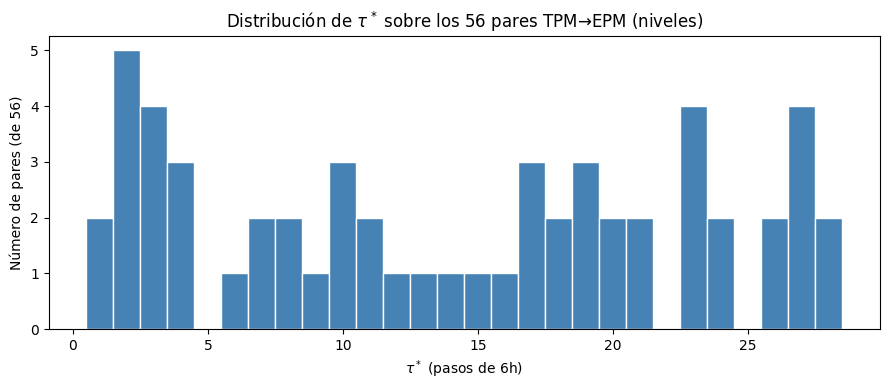

niveles_tau_optimo_fwd
1     2
2     5
3     4
4     3
6     1
7     2
8     2
9     1
10    3
11    2
12    1
13    1
14    1
15    1
16    1
17    3
18    2
19    3
20    2
21    2
23    4
24    2
26    2
27    4
28    2
Name: count, dtype: int64


In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(resultados_te['niveles_tau_optimo_fwd'], bins=range(1, 30), color='steelblue', edgecolor='white', align='left')
ax.set_xlabel(r'$\tau^*$ (pasos de 6h)')
ax.set_ylabel('Número de pares (de 56)')
ax.set_title(r'Distribución de $\tau^*$ sobre los 56 pares TPM→EPM (niveles)')
plt.tight_layout()
plt.savefig(IMG_DIR / 'histograma_tau_optimo.png', dpi=150)
plt.show()

print(resultados_te['niveles_tau_optimo_fwd'].value_counts().sort_index())


## 5. Asimetría direccional con banda nula (no un solo umbral)

**Corrección del punto 6:** antes se dibujaba una sola línea horizontal (el umbral al rezago óptimo). Aquí se dibuja la **banda nula al 95% en cada rezago** (desplazamiento circular, igual metodología que la prueba de significancia), así se ve si la curva observada se despega de la nula en general o solo en un punto aislado.

Por costo computacional (cada par necesita 199 sustitutos x 28 rezagos solo para la banda), se grafican unos pocos pares representativos, no los 56 — el par de referencia (Tilt(2)→Sensor 4), el mejor par por CCM ya usado en la presentación (POT(1)→Sensor 1), y los dos pares que sobreviven con menor p-valor corregido. El bucle está escrito para que extenderlo a más pares sea trivial (solo agregar a `pares_a_graficar`).

In [8]:
def banda_nula_por_lag(fuente, objetivo, lags=LAGS, n_sur=N_SUR, rng=None):
    """Nula por desplazamiento circular, TE en CADA rezago (no solo el maximo),
    para poder graficar una banda en vez de una sola linea horizontal."""
    if rng is None:
        rng = np.random.default_rng(0)
    n = len(fuente)
    matriz_nula = np.zeros((n_sur, len(lags)))
    for s in range(n_sur):
        k = rng.integers(30, n - 30)
        f_shift = np.roll(fuente, k)
        for j, l in enumerate(lags):
            matriz_nula[s, j] = transfer_entropy(f_shift, objetivo, int(l))
    return np.percentile(matriz_nula, 95, axis=0)


pares_mejores_fix = resultados_te.sort_values('niveles_p_corregido').head(2)[['TPM', 'EPM']].values.tolist()
pares_a_graficar = [('Tilt(2)', 'Sensor 4 (10m)'), ('POT(1)', 'Sensor 1 (5m)')] + [tuple(p) for p in pares_mejores_fix]
pares_a_graficar = list(dict.fromkeys(pares_a_graficar))  # quita duplicados preservando orden
print('Pares a graficar:', pares_a_graficar)


Pares a graficar: [('Tilt(2)', 'Sensor 4 (10m)'), ('POT(1)', 'Sensor 1 (5m)'), ('POT(7)', 'Sensor 4 (10m)'), ('Tilt(5)', 'Sensor 4 (10m)')]


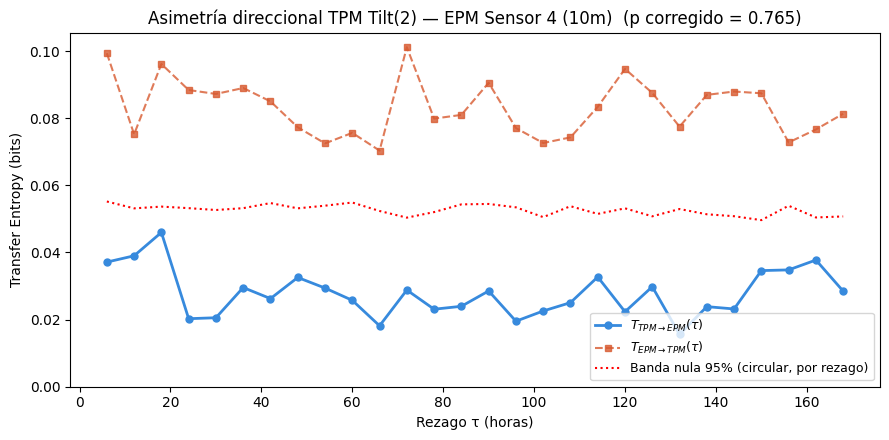

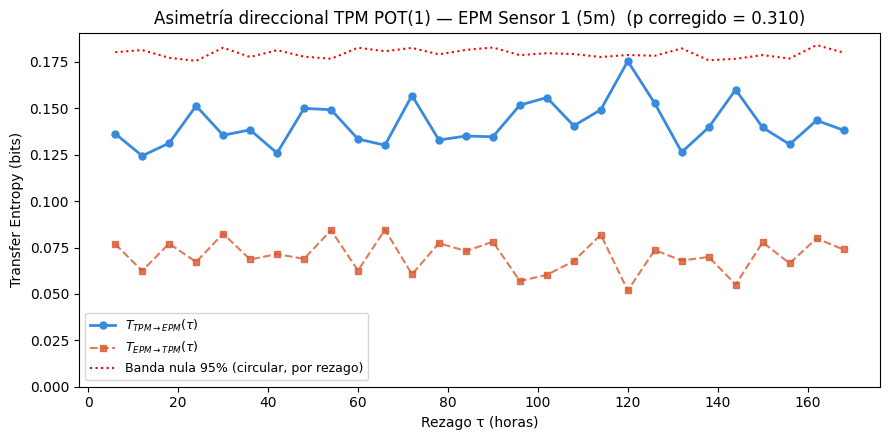

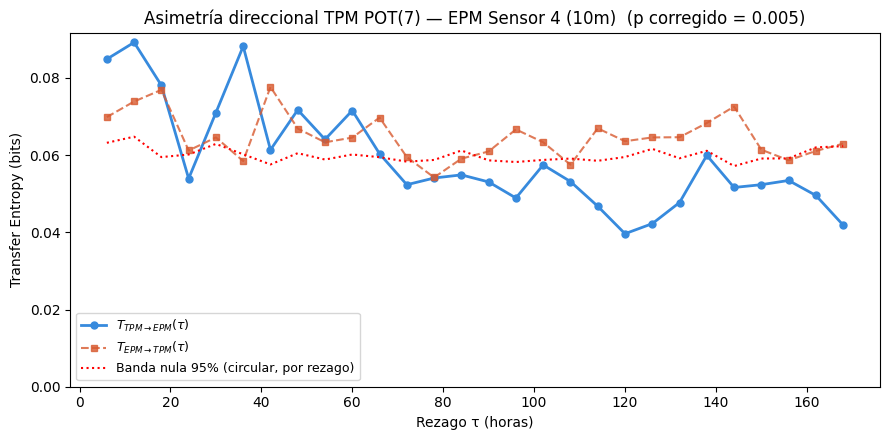

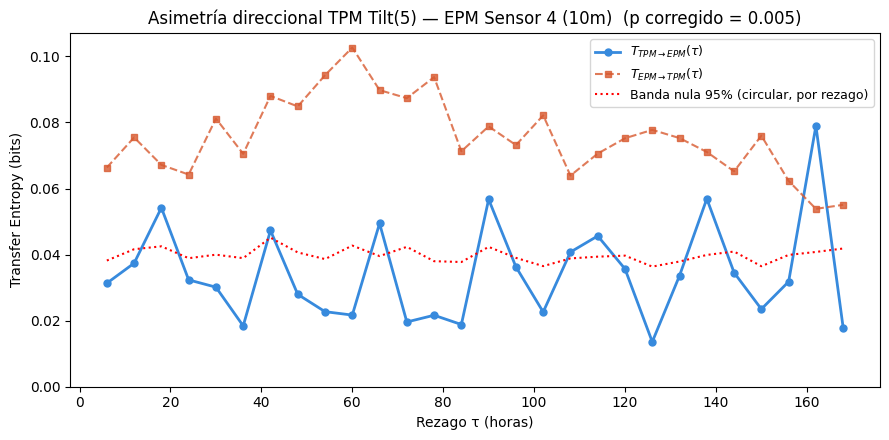

In [9]:
for tpm_col, epm_col in pares_a_graficar:
    src = df_niveles[tpm_col].values
    tgt = df_niveles[epm_col].values

    r_fwd = te_por_lags(src, tgt)
    r_bwd = te_por_lags(tgt, src)

    rng_banda = np.random.default_rng(hash((tpm_col, epm_col, 'banda')) % (2**32))
    banda95 = banda_nula_por_lag(src, tgt, rng=rng_banda)

    fila_res = resultados_te[(resultados_te['TPM'] == tpm_col) & (resultados_te['EPM'] == epm_col)].iloc[0]
    p_fix = fila_res['niveles_p_corregido']

    lag_horas = LAGS * PASO_H

    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(lag_horas, r_fwd['te_por_lag'], 'o-', color='#378ADD', lw=2, markersize=5,
            label=fr'$T_{{TPM \to EPM}}(\tau)$')
    ax.plot(lag_horas, r_bwd['te_por_lag'], 's--', color='#D85A30', lw=1.5, markersize=4, alpha=0.8,
            label=fr'$T_{{EPM \to TPM}}(\tau)$')
    ax.plot(lag_horas, banda95, ':', color='red', lw=1.5, label='Banda nula 95% (circular, por rezago)')
    ax.set_xlabel('Rezago τ (horas)')
    ax.set_ylabel('Transfer Entropy (bits)')
    ax.set_title(f'Asimetría direccional TPM {tpm_col} — EPM {epm_col}  (p corregido = {p_fix:.3f})')
    ax.set_ylim(bottom=0)
    ax.legend(fontsize=9)
    plt.tight_layout()
    nombre = f"{tpm_col}_{epm_col}".replace(' ', '_').replace('(', '').replace(')', '')
    plt.savefig(IMG_DIR / f'te_banda_nula_{nombre}.png', dpi=150)
    plt.show()


## 6. Heatmaps finales (niveles): te_max y significancia corregida

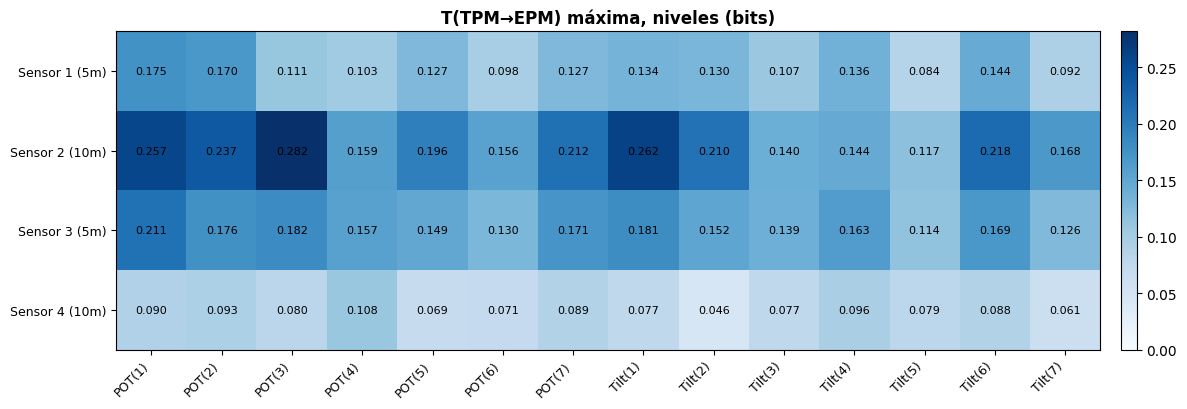

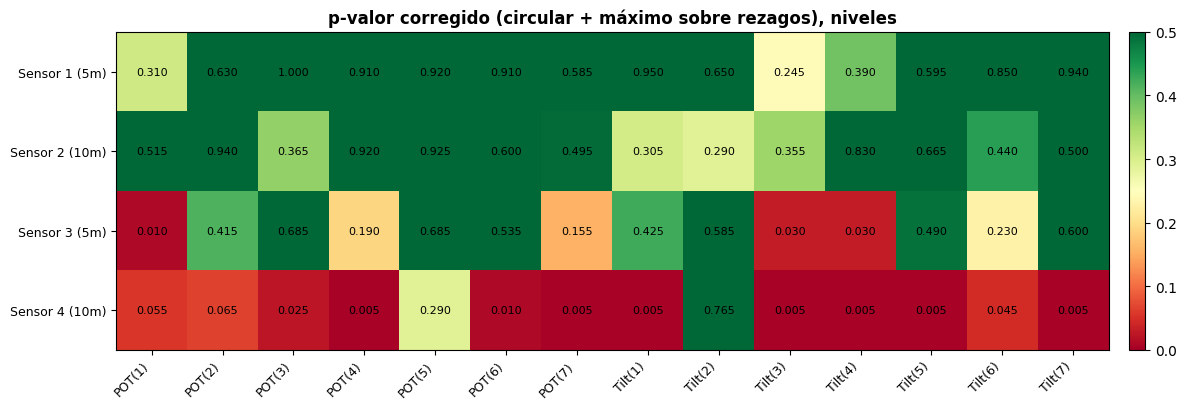

In [10]:
def pivotear(df_largo, columna_valor):
    return df_largo.pivot(index='EPM', columns='TPM', values=columna_valor).reindex(
        index=series_epm, columns=series_tpm
    )


def graficar_heatmap(matriz, titulo, archivo, cmap, vmin=None, vmax=None, fmt='.3f'):
    fig, ax = plt.subplots(figsize=(12, 4.2))
    im = ax.imshow(matriz.values, cmap=cmap, aspect='auto', vmin=vmin, vmax=vmax)
    fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
    for i in range(matriz.shape[0]):
        for j in range(matriz.shape[1]):
            valor = matriz.values[i, j]
            ax.text(j, i, f'{valor:{fmt}}', ha='center', va='center', fontsize=8)
    ax.set_xticks(range(len(matriz.columns)))
    ax.set_xticklabels(matriz.columns, rotation=45, ha='right', fontsize=9)
    ax.set_yticks(range(len(matriz.index)))
    ax.set_yticklabels(matriz.index, fontsize=9)
    ax.set_title(titulo, fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig(IMG_DIR / archivo, dpi=150)
    plt.show()


mat_te = pivotear(resultados_te, 'niveles_te_max_fwd')
mat_p_corr = pivotear(resultados_te, 'niveles_p_corregido')

graficar_heatmap(mat_te, 'T(TPM→EPM) máxima, niveles (bits)', 'heatmap_te_max_corregido.png', cmap='Blues', vmin=0)
graficar_heatmap(mat_p_corr, 'p-valor corregido (circular + máximo sobre rezagos), niveles',
                  'heatmap_pvalor_corregido.png', cmap='RdYlGn', vmin=0, vmax=0.5)


## 7. CCM — correcciones de código (punto 7)

Correcciones aplicadas al código original:
- `lib_range`/`pred_range` ya no están hardcodeados a 881 (dataset viejo) — se calculan de `len(df_tpmepm)`.
- El bucle ya no pisa las variables `tpm`/`epm` (que son los DataFrames) — se usan `tpm_col`/`epm_col`.
- `maxE` baja de 40 a 12: con ~600 puntos de librería, E=40 es excesivo frente a la práctica estándar de EDM (E pequeño relativo al tamaño de librería evita sobreajustar la reconstrucción del atractor; la mayoría de sistemas geofísicos reales necesitan E entre 2 y 10).
- `exclusionRadius`: se intentó justificar con el primer cruce por cero de la autocorrelación, pero **las series en niveles no decorrelacionan dentro de 40 pasos (10 días)** — consistente con el punto 4 (no estacionariedad, dominadas por tendencia). En diferencias, decorrelacionan en 1 paso. No hay un valor "correcto" limpio para niveles; se deja `exclusionRadius=10` pero **marcado explícitamente como convención, no como valor derivado**, y se recomienda reportar esto así en la tesis.
- **Semántica de columnas de pyEDM, verificada empíricamente** (sistema sintético con causalidad conocida: X autónomo, Y depende de X): `pyEDM.CCM(columns=[A], target=[B])` devuelve columnas `A:B` y `B:A`, donde `A:B` es "usar el manifold de A para predecir B". Las etiquetas `skill_TPMmanifold_predice_EPM` / `skill_EPMmanifold_predice_TPM` del código original **están asignadas correctamente** (no invertidas) como descripción mecánica de la operación — no es un bug, queda verificado.

In [11]:
import pyEDM
from itertools import product

df_tpmepm = df_niveles[series_tpm + series_epm].copy()
n_tpmepm = len(df_tpmepm)

lib_end = int(n_tpmepm * 0.68)
lib_range = f'1 {lib_end}'
pred_range = f'{lib_end + 1} {n_tpmepm}'
maxE = 12  # antes 40 -- ver justificacion en la celda markdown de arriba
exclusionRadius = 10  # convencion, no derivado -- ver justificacion arriba

print(f'N = {n_tpmepm}, lib_range = "{lib_range}", pred_range = "{pred_range}"')


N = 889, lib_range = "1 604", pred_range = "605 889"


### CCM: paso caro, opcional

**Advertencia de costo:** `EmbedDimension` + `CCM` + prueba de sustitutos (circular) para los 56 pares puede tardar del orden de horas, igual que en el notebook original. Se deja como celda aparte, sin correr por defecto. Para correrla, cambiar `CORRER_CCM_COMPLETO = True`.

In [12]:
CORRER_CCM_COMPLETO = False  # cambiar a True para correr el bloque completo (horas)

if CORRER_CCM_COMPLETO:
    columnas_tpm_epm = series_tpm + series_epm
    tabla_E = []
    for col in columnas_tpm_epm:
        resultado = pyEDM.EmbedDimension(
            dataFrame=df_tpmepm, lib=lib_range, pred=pred_range, maxE=maxE,
            columns=[col], target=[col], showPlot=False,
        )
        tabla_E.append({'serie': col, 'E_optimo': resultado.loc[resultado['rho'].idxmax(), 'E'],
                        'rho_max': resultado['rho'].max()})
    tabla_E = pd.DataFrame(tabla_E)
    E_optimo = tabla_E.set_index('serie')['E_optimo'].to_dict()
    print(tabla_E)

    def ccm_surrogate_circular(df_base, tpm_col, epm_col, E_par, lib_sizes, n_sur=49, rng=None):
        """Prueba de sustitutos para CCM via desplazamiento circular del TPM."""
        if rng is None:
            rng = np.random.default_rng(0)
        res_obs = pyEDM.CCM(dataFrame=df_base, E=E_par, columns=[tpm_col], target=[epm_col],
                             libSizes=lib_sizes, sample=100, exclusionRadius=exclusionRadius, showPlot=False)
        col_tpm_a_epm = res_obs.columns[1]
        skill_obs = res_obs.sort_values('LibSize').iloc[-1][col_tpm_a_epm]

        n = len(df_base)
        nula = []
        df_perm = df_base.copy()
        for _ in range(n_sur):
            k = rng.integers(30, n - 30)
            df_perm[tpm_col] = np.roll(df_base[tpm_col].values, k)
            res_null = pyEDM.CCM(dataFrame=df_perm, E=E_par, columns=[tpm_col], target=[epm_col],
                                  libSizes=f'{n} {n} 1', sample=30, exclusionRadius=exclusionRadius, showPlot=False)
            nula.append(res_null.iloc[0][col_tpm_a_epm])
        p_valor = (1 + int(np.sum(np.array(nula) >= skill_obs))) / (n_sur + 1)
        return skill_obs, p_valor

    resultados_ccm = []
    for i, (tpm_col, epm_col) in enumerate(product(series_tpm, series_epm)):
        print(f'[{i+1}/56] {tpm_col} vs {epm_col}...', flush=True)
        E_par = max(E_optimo[tpm_col], E_optimo[epm_col])
        inicio = E_par + 10
        lib_sizes_par = f'{inicio} {lib_end} 40'
        rng_par = np.random.default_rng(hash((tpm_col, epm_col, 'ccm')) % (2**32))
        skill_obs, p_valor = ccm_surrogate_circular(df_tpmepm, tpm_col, epm_col, E_par, lib_sizes_par, rng=rng_par)
        resultados_ccm.append({'TPM': tpm_col, 'EPM': epm_col, 'E_par': E_par,
                                'skill_TPMmanifold_predice_EPM': skill_obs, 'p_circular': p_valor})

    resumen_ccm = pd.DataFrame(resultados_ccm)
    resumen_ccm.to_csv('ccm_resultados_corregidos.csv', index=False)
    print(f"CCM significativos (circular, p<0.05): {(resumen_ccm['p_circular']<0.05).sum()}/56")
else:
    print('CORRER_CCM_COMPLETO = False -- bloque omitido. Cambiar a True para correrlo (horas).')


CORRER_CCM_COMPLETO = False -- bloque omitido. Cambiar a True para correrlo (horas).


## 8. Reporte final agregado (no variables sueltas del último par del loop)

**Corrección del punto 8**: el reporte original imprimía `tau_optimo`, `te_max`, `p_valor`, etc. tal cual quedaron tras el último par procesado en el bucle anterior — no era un resumen de los 56 pares, era el resultado de uno solo, elegido por accidente de orden de ejecución. Aquí se construye una tabla con los 56.

También se corrige el lenguaje: **"asimetría direccional"**, no "asimetría causal"; se evita la palabra "causalidad" — esto es evidencia de dependencia estadística dirigida, consistente con lo que ya dice la presentación (`presentacion_seminario_4.tex`: "Predictibilidad incremental dirigida MPT→EPM, no causalidad física").

In [13]:
print('=' * 70)
print('  REPORTE AGREGADO — Transfer Entropy EPM-TPM (revisión rigurosa)')
print('=' * 70)
print()
print(f'Pares evaluados: 56 (14 series TPM × 4 sensores EPM)')
print(f'N nominal: {n_nominal}  |  N real (sin fabricar datos en los bordes): {n_nominal - n_con_nan}')
print()
print('Significativos (niveles):')
print(f'  Método anterior (permutación completa, τ fijo):        {n_naive_niv}/56')
print(f'  Método corregido (circular + máximo sobre rezagos):    {n_fix_niv}/56')
print(f'  Corregido + Benjamini-Hochberg (comparaciones múltiples): {n_bh_niv}/56')
print()
print('Significativos (primeras diferencias, robustez a no estacionariedad):')
print(f'  Método anterior:                                       {n_naive_dif}/56')
print(f'  Método corregido:                                      {n_fix_dif}/56')
print(f'  Corregido + Benjamini-Hochberg:                        {n_bh_dif}/56')
print()
print('Conclusión (dependencia estadística dirigida, NO causalidad física):')
if n_bh_niv == 0:
    print('  Con la prueba de significancia correctamente especificada, ningún par')
    print('  sobrevive la corrección por comparaciones múltiples. Las cifras "55 de 56"')
    print('  / "53 de 56" de la presentación actual reflejan un sesgo metodológico de')
    print('  la prueba anterior (nula de permutación completa + sesgo de selección),')
    print('  no evidencia robusta de dependencia direccional.')
else:
    print(f'  {n_bh_niv} de 56 pares sobreviven incluso tras la corrección más estricta.')
print('=' * 70)


  REPORTE AGREGADO — Transfer Entropy EPM-TPM (revisión rigurosa)

Pares evaluados: 56 (14 series TPM × 4 sensores EPM)
N nominal: 889  |  N real (sin fabricar datos en los bordes): 885

Significativos (niveles):
  Método anterior (permutación completa, τ fijo):        56/56
  Método corregido (circular + máximo sobre rezagos):    13/56
  Corregido + Benjamini-Hochberg (comparaciones múltiples): 7/56

Significativos (primeras diferencias, robustez a no estacionariedad):
  Método anterior:                                       56/56
  Método corregido:                                      6/56
  Corregido + Benjamini-Hochberg:                        0/56

Conclusión (dependencia estadística dirigida, NO causalidad física):
  7 de 56 pares sobreviven incluso tras la corrección más estricta.


## 9. Exportar CSV de entrega

In [14]:
entrega = resultados_te.copy()
entrega.to_csv('tpm_ccm_revision_rigurosa_resultados.csv', index=False)
print('Guardado: tpm_ccm_revision_rigurosa_resultados.csv')
print(f'Columnas: {list(entrega.columns)}')


Guardado: tpm_ccm_revision_rigurosa_resultados.csv
Columnas: ['TPM', 'EPM', 'niveles_tau_optimo_fwd', 'niveles_te_max_fwd', 'niveles_te_max_bwd', 'niveles_N_efectivo_fwd', 'niveles_bins_efectivos_tpm', 'niveles_bins_efectivos_epm', 'niveles_p_naive', 'niveles_p_corregido', 'diferencias_tau_optimo_fwd', 'diferencias_te_max_fwd', 'diferencias_te_max_bwd', 'diferencias_N_efectivo_fwd', 'diferencias_bins_efectivos_tpm', 'diferencias_bins_efectivos_epm', 'diferencias_p_naive', 'diferencias_p_corregido', 'niveles_p_BH_sig', 'diferencias_p_BH_sig']
